Notebook ini menjelaskan apa yang dikerjakan kode EXP-001 dan jejaknya. Angka di bawah dibaca dari artifact hasil run yang sebenarnya, bukan dihitung ulang dari data mentah.

## 1. Data dan pertanyaan

Config menetapkan seed, arsip ITSP, dan 20 butir yang dipakai.

```python
def load_config(path: Path) -> dict:
    with path.open(encoding="utf-8") as fh:
        return yaml.safe_load(fh)
```

In [1]:
import json
import sys
import yaml
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
D = ROOT / "experiments" / "EXP-001"

cfg = yaml.safe_load((D / "config.yaml").read_text(encoding="utf-8"))
manifest = json.loads((D / "data-manifest.json").read_text(encoding="utf-8"))
print(json.dumps({
    "seed": cfg["seed"],
    "dataset": cfg["data"]["name"],
    "commit": cfg["data"]["commit"],
    "sha256": cfg["data"]["sha256"],
    "n_items": cfg["data"]["n_items"],
    "n_items_available": manifest["n_items_available"],
}, indent=2))

{
  "seed": 20261123,
  "dataset": "ITSP",
  "commit": "0553f683f99403efb5ef440af826c1d229a52376",
  "sha256": "7d2329ca5cd1009ee0c7518095a13b18fb82a6931750ece27014a83f5d13dec0",
  "n_items": 20,
  "n_items_available": 661
}


## 2. Dari arsip ke 20 butir

Fungsi ini memilih butir secara deterministik dari dataset hasil ekstraksi.

```python
def load_items(cfg: dict) -> list[dict]:
    data = dataset_root(cfg)
    items: list[dict] = []
    for main in sorted(data.glob("Lab-*/*/Main.c")):
        lab, prob_id = main.parent.parent.name, main.parent.name
        tests = []
        for inp in sorted(
            (data / "test").glob(f"in.{prob_id}.*.txt"),
            key=lambda p: int(p.name.split(".")[-2]),
        ):
            idx = inp.name.split(".")[-2]
            out = data / "test" / f"out.{prob_id}.{idx}.txt"
            if out.is_file():
                tests.append((inp.read_text(encoding="utf-8", errors="replace"),
                              out.read_text(encoding="utf-8", errors="replace")))
        for buggy in sorted(main.parent.glob("*_buggy.c")):
            student = buggy.name.removesuffix("_buggy.c")
            correct = main.parent / f"{student}_correct.c"
            if not correct.is_file() or not tests:
                continue
            items.append({
                "item_id": f"{lab}-{prob_id}-{student}",
                "lab": lab,
                "difficulty_proxy": int(lab.split("-")[-1]),
                "statement": statement_from_main(main),
                "buggy_code": buggy.read_text(encoding="utf-8", errors="replace"),
                "correct_code": correct.read_text(encoding="utf-8", errors="replace"),
                "tests": tests,
            })
    return items
```

In [2]:
metrics = json.loads((D / "metrics.json").read_text(encoding="utf-8"))
print(json.dumps(metrics["data"], indent=2))

{
  "name": "ITSP",
  "commit": "0553f683f99403efb5ef440af826c1d229a52376",
  "archive_sha256": "7d2329ca5cd1009ee0c7518095a13b18fb82a6931750ece27014a83f5d13dec0",
  "n_items_available": 661,
  "n_items_selected": 20
}


## 3. Kompilasi dan fail-to-pass

Kode buggy dan benar dikompilasi, lalu dibandingkan jumlah test yang lulus.

```python
def execution_metrics(items: list[dict], cfg: dict, trace: RunLog) -> tuple[list[dict], dict]:
    results = []
    with tempfile.TemporaryDirectory() as td:
        work = Path(td)
        for item in items:
            item_id = item["item_id"]
            with trace.item(item_id):
                buggy = compile_and_run(
                    item["buggy_code"], item["tests"], work, cfg, trace, "buggy", item_id
                )
                correct = compile_and_run(
                    item["correct_code"], item["tests"], work, cfg, trace, "correct", item_id
                )
                for variant, result in (("buggy", buggy), ("correct", correct)):
                    trace.event(
                        "item_executed", variant=variant, compiled=result["compiled"],
                        passed=result["passed"], total=result["total"],
                    )
                trace.event(
                    "item_compiled",
                    buggy_compiled=buggy["compiled"], correct_compiled=correct["compiled"],
                    buggy_passed=buggy["passed"], correct_passed=correct["passed"],
                    total=buggy["total"],
                )
            results.append({"item_id": item_id, "buggy": buggy, "correct": correct})
    n = len(results)
    fail_to_pass = sum(
        1 for r in results
        if r["buggy"]["compiled"] and r["correct"]["compiled"]
        and r["buggy"]["passed"] < r["correct"]["passed"]
    )
    return results, {
        "n_items": n,
        "buggy_compiled": sum(r["buggy"]["compiled"] for r in results),
        "correct_compiled": sum(r["correct"]["compiled"] for r in results),
        "fail_to_pass_items": fail_to_pass,
        "fail_to_pass_rate": round(fail_to_pass / n, 4) if n else 0.0,
    }
```

In [3]:
print(json.dumps(metrics["execution"], indent=2))

{
  "n_items": 20,
  "buggy_compiled": 17,
  "correct_compiled": 16,
  "fail_to_pass_items": 14,
  "fail_to_pass_rate": 0.7
}


## 4. Prompt dan judge

Empat panggilan LLM per butir menghasilkan kandidat, seleksi, rewrite, dan skor.

```python
def call_llm_traced(
    cfg: dict, messages: list[dict], session: str,
    trace: RunLog, module: str,
```

In [4]:
print(json.dumps(metrics["generation"], indent=2))

{
  "n_items": 20,
  "judge_parseable": 20,
  "mean_by_dimension": {
    "collaboration": 4.15,
    "cooperation": 4.0,
    "negotiation": 3.55,
    "ideas_sharing": 4.2
  }
}


## 5. Trace core

RunLog menulis event append-only, menghitung attempt, dan menolak config yang berubah.

```python
    def _next_attempt(self) -> int:
        if not self.events_path.is_file():
            return 1
        attempts = []
        for line in self.events_path.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            event = json.loads(line)
            previous = event.get("config_sha256")
            if previous is not None and previous != self.config_sha256:
                raise ConfigChangedError(
                    f"{self.events_path} holds config_sha256={previous}; "
                    f"current config_sha256={self.config_sha256}"
                )
            if isinstance(event.get("attempt"), int):
                attempts.append(event["attempt"])
        return max(attempts, default=0) + 1

    def _write(self, name: str, **payload: Any) -> None:
        event = {
            "event": name,
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "t_s": round(monotonic() - self._mono_start, 3),
            "run_id": self.run_id,
            "attempt": self.attempt,
        }
        if self._stage:
            event["stage"] = self._stage
        if self._item_id:
            event["item_id"] = self._item_id
        event.update(payload)
        self._fh.write(json.dumps(event, ensure_ascii=False, default=str) + "\n")
        self._fh.flush()

    def start(self, *, mode: str, config_sha256: str | None = None, **payload: Any) -> None:
        self._write(
            "started",
            mode=mode,
            config_sha256=config_sha256 or self.config_sha256,
            git_sha=git_sha(self.repo),
            **payload,
        )
```

In [5]:
from collections import Counter

events = [
    json.loads(line)
    for line in (D / "events.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
print(json.dumps({
    "events": len(events),
    "by_name": dict(Counter(event["event"] for event in events)),
    "attempts": sorted({
        event.get("attempt") for event in events if event.get("attempt") is not None
    }),
}, indent=2))

{
  "events": 410,
  "by_name": {
    "failed": 1,
    "started": 3,
    "stage_started": 11,
    "stage_completed": 11,
    "item_executed": 120,
    "item_compiled": 60,
    "compile_failed": 21,
    "completed": 3,
    "item_prompted": 80,
    "judge_scored": 80,
    "item_parsed": 20
  },
  "attempts": [
    1,
    2,
    3
  ]
}


## 6. Provenance dan artifact lokal

Provenance mencatat versi dan hash, sementara teks mentah tetap di folder yang diabaikan git.

```python
    def write_provenance(self, **extra: Any) -> None:
        payload: dict[str, Any] = {
            "experiment": self.experiment_id,
            "run_id": self.run_id,
            "attempt": self.attempt,
            "config_sha256": self.config_sha256,
            "git_sha": git_sha(self.repo),
            "started_utc": self.started_utc,
            "python": platform.python_version(),
            "platform": platform.platform(),
            "wall_time_s": self._wall_time(),
        }
        if resource is not None:
            payload["peak_rss_mb"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 2)
        payload.update(extra)
        self.provenance_path.write_text(
            json.dumps(payload, indent=2, default=str) + "\n", encoding="utf-8"
        )
```

In [6]:
provenance = json.loads((D / "provenance.json").read_text(encoding="utf-8"))
local = ROOT / "experiments" / "outputs" / "EXP-001"
print(json.dumps(provenance, indent=2))
print("local files:", len(list(local.glob("*"))))
print("figures:", [path.name for path in sorted((local / "figures").glob("*.png"))])

{
  "experiment": "EXP-001",
  "run_id": "EXP-001-20261124T035513458240Z-f8283ecc",
  "attempt": 3,
  "config_sha256": "f8283ecc6edd0d528b403ce61030e7d53cb1a01cc39df1913aaec23e549cbde8",
  "git_sha": "29bad9fc2ea313b90d198e1b684ff5bdba6e380f",
  "started_utc": "2026-11-24T03:55:13.458225+00:00",
  "python": "3.13.16",
  "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.43",
  "wall_time_s": 275.433,
  "peak_rss_mb": 34.35,
  "data_sha256": "7d2329ca5cd1009ee0c7518095a13b18fb82a6931750ece27014a83f5d13dec0",
  "gcc": "gcc (Ubuntu 15.2.0-16ubuntu1) 15.2.0",
  "pyyaml": "6.0.4",
  "model": "deepseek-v4.1-flash",
  "gateway": "https://opencode.ai/inference/go",
  "n_items": 20
}
local files: 158
figures: ['failure_breakdown.png', 'judge_scores.png', 'pass_rate_per_item.png', 'stage_timeline.png']


## 7. Visualisasi

Empat plot dibaca dari artifact dan ditampilkan di sini tanpa menghitung ulang angka.

```python
def main() -> None:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    summary = summarize(load_events(EXP_DIR / "events.jsonl"))
    metrics = json.loads((EXP_DIR / "metrics.json").read_text(encoding="utf-8"))
    plot_stage_timeline(summary)
    plot_pass_rates(metrics)
    plot_judge(metrics)
    plot_failures(summary, metrics)
    print(f"figures: {OUT_DIR}")
```

['failure_breakdown.png', 'judge_scores.png', 'pass_rate_per_item.png', 'stage_timeline.png']


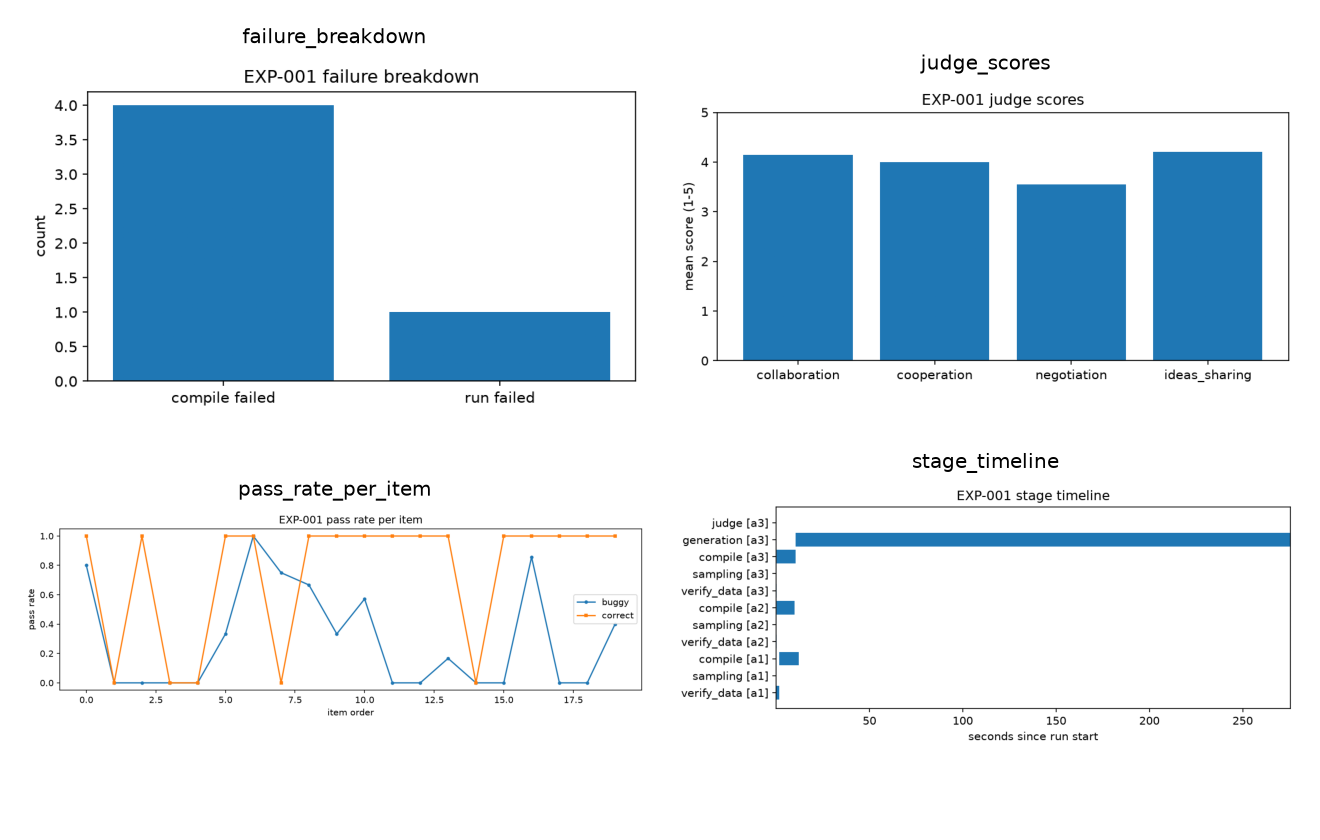

In [7]:
import matplotlib.pyplot as plt

fig_dir = local / "figures"
paths = sorted(fig_dir.glob("*.png"))
print([path.name for path in paths])
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, path in zip(axes.ravel(), paths):
    ax.imshow(plt.imread(path))
    ax.axis("off")
    ax.set_title(path.stem)
plt.tight_layout()
plt.show()